# <font color="#0b486b">FIT3181 | FIT5215: Deep Learning (2026)</font>
***

*CE/Lecturer (Clayton):* **Dr [Trung Le](mailto:trunglm@monash.edu)** <br/>
*Lecturer (Clayton):* **Dr [Binh Nguyen](mailto:binh.nguyen1@monash.edu)** <br/>
*Lecturer (Malaysia):*  **Dr [Arghya Pal](mailto:arghya.pal@monash.edu)**, **Dr [Sailaja Rajanala](mailto:sailaja.rajanala@monash.edu)**, **Dr [Sicily Fung Fung Ting](mailto:ting.fung@monash.edu)** <br/>
*Head Tutor (Clayton):* **Mr [Minh Vo](mailto:minh.vo1@monash.edu)** (FIT3181), **Dr [Ruda Nie H](mailto:rudanie.h@monash.edu)** (FIT5215)<br/> <br/>

Faculty of Information Technology, Monash University, Australia
***

# <font color="#0b486b">Tutorial 11a: Generative Adversarial Networks</font>

The purpose of this tutorial is to demonstrate how to work with Generative Adversarial Network (GAN), "the coolest idea in machine learning in the last ten years" - Yann Lecun, Director of Facebook AI Research. In this tutorial, we will provide a comprehensive study of GANs from the practical aspects. <br/>

Below are some good references:
- Tutorial of GANs and generative models from Ian Goodfellow [link](https://arxiv.org/pdf/1701.00160.pdf) and [video link](https://www.youtube.com/watch?v=HGYYEUSm-0Q&ab_channel=StevenVanVaerenbergh).
- The paper `Improve Techniques of Trainining GANs` [link](https://arxiv.org/pdf/1606.03498.pdf) which proposed DC-GAN and Inception score.
- The paper `Improved Training of Wasserstein GANs` [link](https://arxiv.org/pdf/1704.00028.pdf) which proposed WGAN with gradient penalty.
- GANs zoo [link](https://github.com/hindupuravinash/the-gan-zoo).

***

# <font color="#0b486b">I. Overview of GANs</font> <font color="red">*****</font> #

## <font color="#0b486b">I.1. Introduction</font> ##

Generative models is an important research direction of AI, which has the goal that learning underlying data distribution of given dataset and so as to generate new data samples with some variations. GAN contains two models called *Generator* and *Discriminator* (sometimes called *Critic*). A *Generator* learns to create fake images that look real, while a *Discriminator* takes images (which can be sampled from a training set or generated from a *Generator*) and learns to distinguish them as being real or fake. <br/>
Two models are trained simultaneously by an adversarial process. The Generator trying to fool the Discriminator by generating more real images, while Discriminator trying to correctly classify real vs. fake images. Theoretically, the Generator can become better after each training epoch, while the Discriminator reaches optimal at every epoch and the adversarial game can reach an optimal point (which is called *equilibrium*) when the Discriminator can no longer distinguish real images and fake images, and Generator can successfully learn the data distribution. <br/>

## <font color="#0b486b">I.2. Optimization of GAN </font>

The original GAN objective loss: <br/>
\begin{equation}
    \underset{G}{\text{minimize}} \; \underset{D}{\text{maximize}} \; \mathbb{E}_{x \sim p_{d}}[ \log{D(x)} ] + \mathbb{E}_{z \sim p_{z}} [\log{1 - D(G(z))}]
\end{equation}
where $x \sim p_d$ means real images were sampled from the training data, $z \sim p_z$ means random samples from the prior distribution. $G()$ is the generative function and $D()$ is the discriminative function. In the [original GAN paper](https://arxiv.org/abs/1406.2661), the authors show that optimize the objective of GAN relating to minimizing the Jensen-Shannon divergence between data distribution $p_d$ and the generated distribution $p_g$. In optimal, $p_g(x) = p_d(x)$ and $D(x)=D(G(z))=1/2$ for any $x \sim p_d(x)$ and $z \sim p_z(z)$. <br/>
To optimize the minimax game, we do optimize two models D and G simultaneously:
1. Update the Generator (G) to minimize the probability of the Discriminator (D) making the correct choice.
2. Update the Discriminator (D) to maximize the probability of the Discriminator making the correct choice.

Empirically, the Discriminator distinguishes real/fake samples easier than the Generator generating real images. Therefore, Discriminator objective loss easily goes to one, while Generator objective loss goes to zero. To make training more stable, we instead use a different Generator objective that maximizes the probability of the Discriminator making the incorrect choice.  

The final optimization strategy for training GAN is as below: <br/>
1. Update the Generator:
\begin{equation}
    \underset{G}{\text{maximize}} \; \mathbb{E}_{z \sim p_{z}} [\log{D(G(z))}]
\end{equation}
2. Update the Discriminator:
\begin{equation}
    \underset{D}{\text{maximize}} \; \mathbb{E}_{x \sim p_{d}}[ \log{D(x)} ] + \mathbb{E}_{z \sim p_{z}} [\log{1 - D(G(z))}]
\end{equation}

## <font color="#0b486b">I.3. Pros and Cons </font>

### <font color="#0b486b">I.3.1. Pros </font>  ###

There are several good properties that make GAN become one of the most breakthrough ideas in machine learning in recent years. <br/>
1. Very few restrictions on the network and objective design. For example, Generator/Discriminator can be MPL, CNN or RNN with flexibility in the use of activation or batch normalization.
2. Produce better quality samples than other generative models.
3. Training much faster than autoregressive models, not require Markov chains as Boltzmann machines, no variational bounds as Variational Autoencoders (VAEs).
4. Easy to apply for different datasets/problems/applications. <br/>

GAN is one of the most attractive trends in AI research (around 490 papers were published in Dec 2018, according to the statistic on [the GAN's zoo website](https://github.com/hindupuravinash/the-gan-zoo))

### <font color="#0b486b">I.3.2. Cons </font>  ###


#### <font color="#0b486b"> i. Mode collapse </font> ####

Mode collapse is the problem when the generator can only generate some modes even the model was trained from a diverse dataset. We can have a sense of this problem through visual examples below:

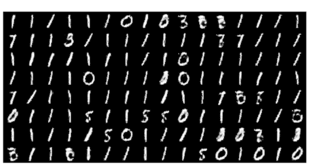

*Mode collapse example 1: Generate only some digits {0, 1, 3, 5, 7} while learning from the MNIST dataset*

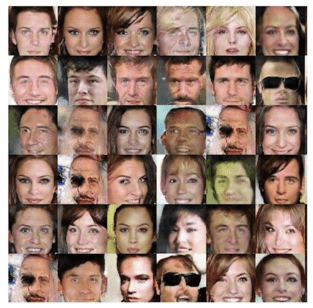

*Mode collapse example 2: Generate only some faces while learning from the CelebA dataset*

#### <font color="#0b486b">ii. Unstable training </font> ####

Unstable training is the problem when the generator cannot converge after a long time of training.

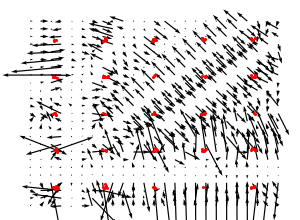

*Unstable training example: This is the gradient map of original GAN's discriminator. The red dots are the true/real data points. The GAN model tries to generate datapoints like real datasets. However, the gradient map looks noisy and disorder, which cannot lead to convergence*

#### <font color="#0b486b"> iii. Unrealistic output </font> ####

Unrealistic output is the problem when the generated image looks not real even the model converged and the discriminator cannot distinguish real or fake samples. It is because the view of the discriminator is different from our visual view.

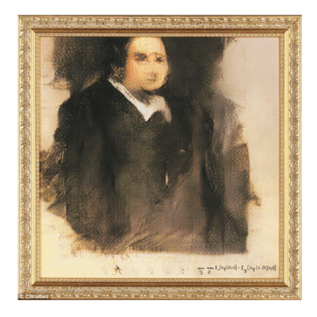

*Unrealistic example: This is a generated art by GAN (reference to CS236-Stanford)*

# <font color="#0b486b">II. Implementation of GANs</font> <font color="red">*****</font> #

## <font color="#0b486b">II.1. Prepare data</font>

We import the necessary packages and modules.

In [ ]:
import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import math

# Set global seed for reproducibility
global_seed = 123
np.random.seed(global_seed)
torch.manual_seed(global_seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Check PyTorch version and if GPU is available
print("\nPyTorch Version: " + torch.__version__)
print("GPU Available: ", torch.cuda.is_available())


PyTorch Version: 2.1.2
GPU Available:  True


We download the dataset and split it into train/test sets.

In [ ]:
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader, Subset

# Define the transform to normalize the data
transform = transforms.Compose([
    transforms.ToTensor(),  # Convert the images to PyTorch tensors
    transforms.Normalize((0.5,), (0.5,))  # Normalize to [0, 1] range and then to [-1, 1]
])

# Load the Fashion-MNIST dataset
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)

# Get the training data and labels
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=len(train_dataset), shuffle=False)

In [ ]:
# Please skip this cell to train on the entire dataset.
# Select 10,000 random indices
num_train = 10000
indices = np.arange(len(train_dataset))
np.random.shuffle(indices)

# Create a subset of the original dataset
subset_indices = indices[:num_train]
train_subset = Subset(train_dataset, subset_indices)

# Create DataLoader for the subset
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)

## <font color="#0b486b">II.2. Abstract general GAN class</font>

We are going to declare the abstract class `GAN` which will be inherited later by other classes. There are some important instance variables:
- `self.noise_dim`: the dimension of the noise space.
- `self.generator`: the generator network that maps from the noise $z$ to generated (fake) examples ($x_g = G(z)$).
- `self.discriminator`: the discriminator network that aims to distinguish the real and fake examples.
- `self.gan`: the entire GAN network including both the generator and discriminator.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

class GAN(nn.Module):
    def __init__(self, data_loader=None, batch_size=32, epochs=10, optimizer=None,
                 noise_dim=30, device='cpu'):
        super(GAN, self).__init__()
        self.batch_size = batch_size  # Batch size for training
        self.epochs = epochs  # Number of training epochs
        self.optimizer = optimizer  # Optimizer class for training
        self.noise_dim = noise_dim  # Dimension of noise vector
        self.device = device  # Device to run the model (CPU/GPU)
        self.generator = None  # Placeholder for generator model
        self.discriminator = None  # Placeholder for discriminator model
        self.gen_optimizer = None  # Placeholder for generator optimizer
        self.dis_optimizer = None  # Placeholder for discriminator optimizer
        self.data_loader = data_loader  # Data loader for training dataset

    @staticmethod
    def plot_multiple_images(images, n_cols=None):
        # Plot a grid of images
        n_cols = n_cols or len(images)
        n_rows = (len(images) - 1) // n_cols + 1
        if images.shape[1] == 1:
            images = images.squeeze(1)  # Remove channel dimension if grayscale
        plt.figure(figsize=(n_cols, n_rows))
        for index, image in enumerate(images):
            plt.subplot(n_rows, n_cols, index + 1)
            plt.imshow(image.cpu().detach().numpy(), cmap="gray")  # Display image
            plt.axis("off")  # Hide axes
        plt.show()

    def build(self):
        pass  # To be implemented in subclasses

    def generate(self, num_examples=None):
        # Generate fake images from random noise
        num_examples = self.batch_size if num_examples is None else num_examples
        z = torch.randn(num_examples, self.noise_dim, device=self.device)  # Random noise
        X_gen = self.generator(z)  # Generate images
        return X_gen

    def train(self):
        self.history = {'disc-loss': [], 'gen-loss': []}  # Track losses
        criterion = nn.BCELoss()  # Binary Cross Entropy loss

        for epoch in range(self.epochs):
            dis_losses = []  # List to store discriminator losses
            gen_losses = []  # List to store generator losses
            for batch_idx, (X_batch, y_batch) in enumerate(self.data_loader):
                X_batch = X_batch.to(self.device)  # Move batch to device

                # PHASE 1 - Train Discriminator
                z = torch.randn(X_batch.size(0), self.noise_dim, device=self.device)  # Random noise
                X_gen = self.generator(z)  # Generate fake images

                X_fake_and_real = torch.cat([X_gen, X_batch], dim=0)  # Combine real and fake images

                y1 = torch.cat([torch.zeros(X_gen.size(0), 1), torch.ones(X_batch.size(0), 1)], dim=0).to(self.device)  # Labels for discriminator

                self.discriminator.train()  # Set discriminator to training mode
                self.dis_optimizer.zero_grad()  # Zero gradients
                dis_loss = criterion(self.discriminator(X_fake_and_real), y1)  # Compute discriminator loss
                dis_loss.backward()  # Backpropagation
                self.dis_optimizer.step()  # Update discriminator weights
                dis_losses.append(dis_loss.item())  # Store loss

                # PHASE 2 - Train Generator
                z = torch.randn(self.batch_size, self.noise_dim, device=self.device)  # New random noise
                y2 = torch.ones(self.batch_size, 1, device=self.device)  # Labels for generator

                self.discriminator.eval()  # Freeze discriminator weights
                self.gen_optimizer.zero_grad()  # Zero gradients
                gen_loss = criterion(self.discriminator(self.generator(z)), y2)  # Compute generator loss
                gen_loss.backward()  # Backpropagation
                self.gen_optimizer.step()  # Update generator weights
                gen_losses.append(gen_loss.item())  # Store loss

            # Log and plot losses
            print(f"Epoch {epoch + 1}/{self.epochs}: disc-loss = {np.mean(dis_losses)}, gen-loss = {np.mean(gen_losses)}")
            self.history['disc-loss'].append(np.mean(dis_losses))  # Record average loss
            self.history['gen-loss'].append(np.mean(gen_losses))

            # Display generated images
            self.plot_multiple_images(self.generate()[:4 * 8], 8)  # Generate and plot images


The method (function) `train` is very important. In each iteration (corresponding to a mini-batch), we train the discriminator and then generator accordingly.
- The task of the discriminator is to discriminate the real and fake (generated) examples. The real examples are stored in $X\_batch$, while the fake examples are stored in $X\_gen$. The label set $y_1$ contains $2 \times batch\_size$ labels for which the first $batch\_size$ labels are $0$ corresponding to fake examples and the last $batch\_size$ labels are $1$ corresponding to real examples.
- The task of the generator is to fool the discriminator. We update the generator to maximize the probabilities to assign $X\_gen$ to class $1$. Therefore, we create $y2$ as a set of desired labels of all $1$s. We then train G to maximize the probabilities to match $X\_gen$ and $y2$. Note that this is equivalent to:
  - $\underset{G}{\text{maximize}} \; \mathbb{E}_{z \sim p_{z}} [\log{D(G(z))}]$ (i.e., moving $G(z)$ to the high-valued region of D which is for the real examples).

## <font color="#0b486b">II.3. Standard GAN</font>

In the standard GAN class, we rewrite and override the code of the `build` method.

In [ ]:
class StandardGAN(GAN):
    def __init__(self, data_loader=None, batch_size=32, epochs=10, optimizer=None, noise_dim=30, device='cpu'):
        super(StandardGAN, self).__init__(data_loader, batch_size, epochs, optimizer, noise_dim, device)

    def build(self):
        # Generator network definition
        self.generator = nn.Sequential(
            nn.Linear(self.noise_dim, 256),  # Maps noise to 256 dimensions
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),  # Upsamples to 512 dimensions
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1024),  # Upsamples to 1024 dimensions
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 784),  # Outputs 784 dimensions (28x28 images)
            nn.Tanh(),
            nn.Unflatten(1, torch.Size([1, 28, 28]))  # Reshapes to image format
        ).to(self.device)

        # Discriminator network definition
        self.discriminator = nn.Sequential(
            nn.Flatten(),  # Flattens input images
            nn.Linear(784, 1024),  # Processes 784-dimensional input
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),  # Reduces to 512 dimensions
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),  # Further reduces to 256 dimensions
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 128),  # Reduces to 128 dimensions
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 1),  # Outputs a single score (real or fake)
            nn.Sigmoid()  # Probability output
        ).to(self.device)

        # Set optimizers for generator and discriminator
        self.dis_optimizer = self.optimizer(self.discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
        self.gen_optimizer = self.optimizer(self.generator.parameters(), lr=2e-4, betas=(0.5, 0.999))


We initialize the standard_GAN object from the `StandardGAN` class and start training.

In [ ]:
standard_GAN = StandardGAN(data_loader=train_loader, batch_size=128, noise_dim=100, optimizer=optim.Adam, epochs=30, device=device)

In [ ]:
standard_GAN.build()

Epoch 1/30: disc-loss = 0.34061572622436626, gen-loss = 1.9258502896424312


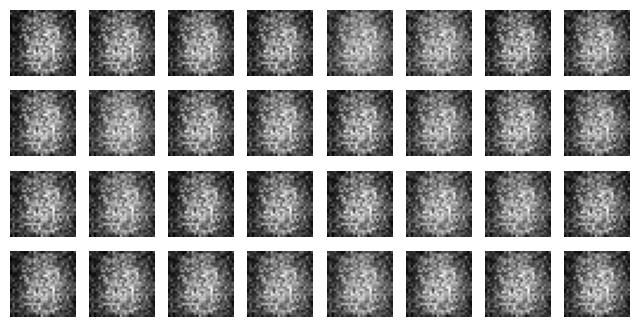

Epoch 2/30: disc-loss = 0.21826659233137302, gen-loss = 3.7889925970393383


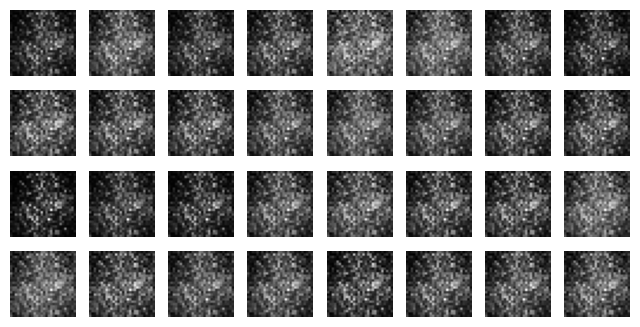

Epoch 3/30: disc-loss = 0.3353616249789098, gen-loss = 2.8268011375597326


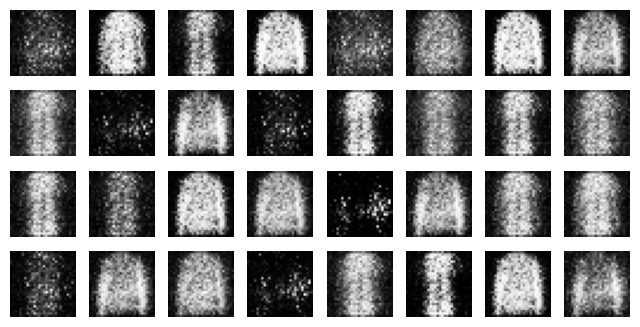

Epoch 4/30: disc-loss = 0.372830354863671, gen-loss = 2.457757934643205


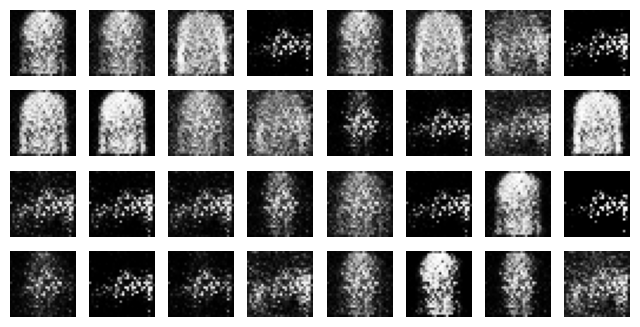

Epoch 5/30: disc-loss = 0.38739372894262813, gen-loss = 2.265148719404913


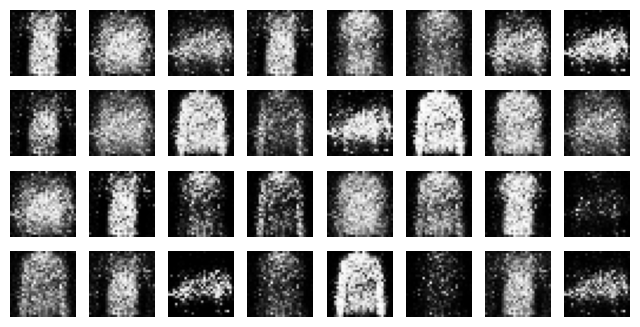

Epoch 6/30: disc-loss = 0.3875682313161291, gen-loss = 2.1558164882052475


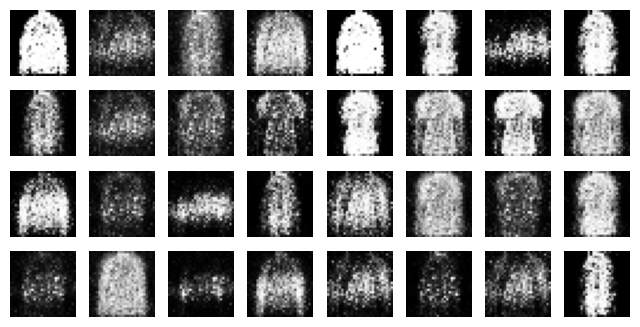

Epoch 7/30: disc-loss = 0.428125602044877, gen-loss = 1.8534462531660771


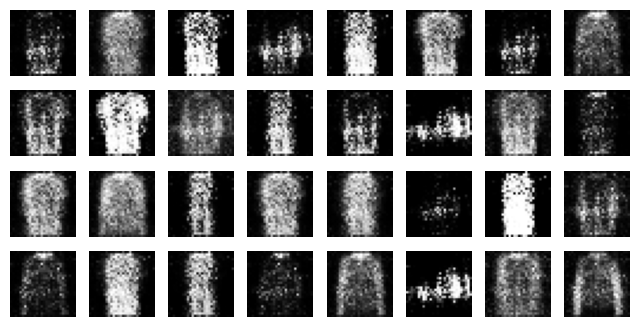

Epoch 8/30: disc-loss = 0.436162002147383, gen-loss = 1.7502970353812928


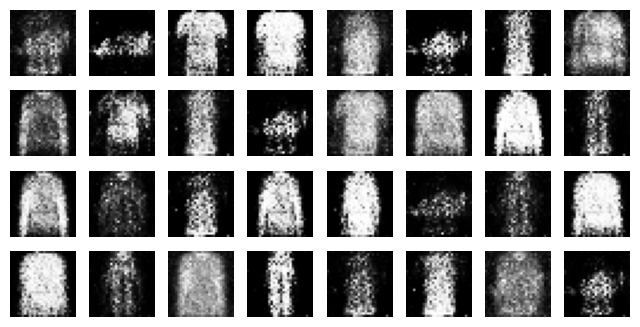

Epoch 9/30: disc-loss = 0.4495179907531495, gen-loss = 1.7055425693275064


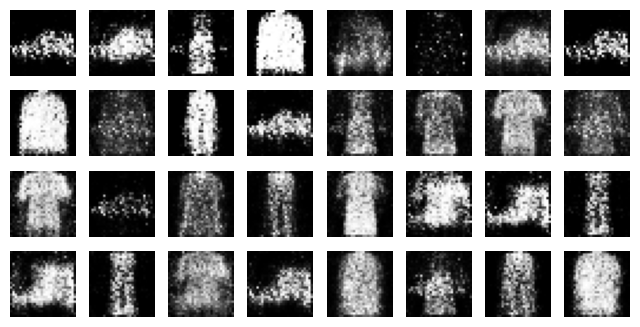

Epoch 10/30: disc-loss = 0.4669778787406387, gen-loss = 1.6180639863014221


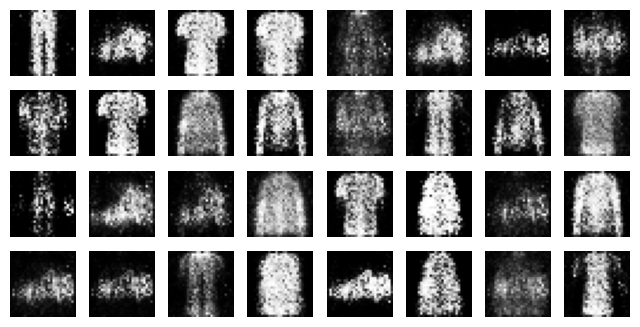

Epoch 11/30: disc-loss = 0.484507517260351, gen-loss = 1.5360208146131722


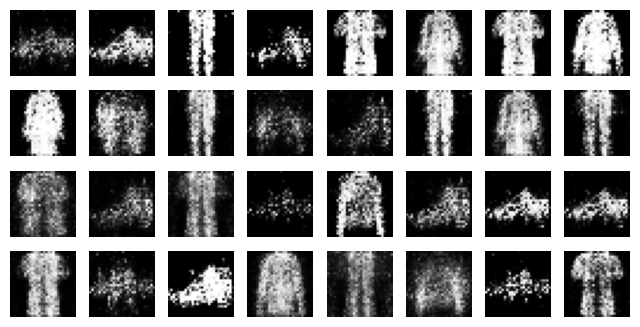

Epoch 12/30: disc-loss = 0.5149046514823938, gen-loss = 1.463014315647684


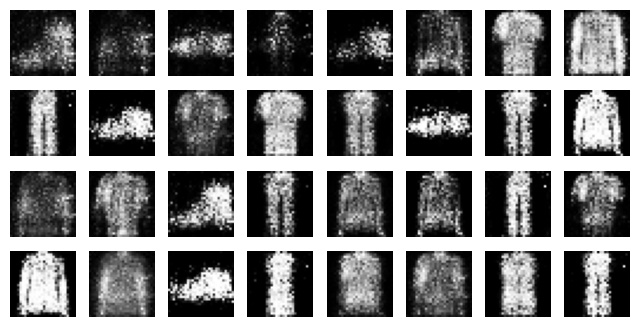

Epoch 13/30: disc-loss = 0.5152038510437984, gen-loss = 1.4512346891840553


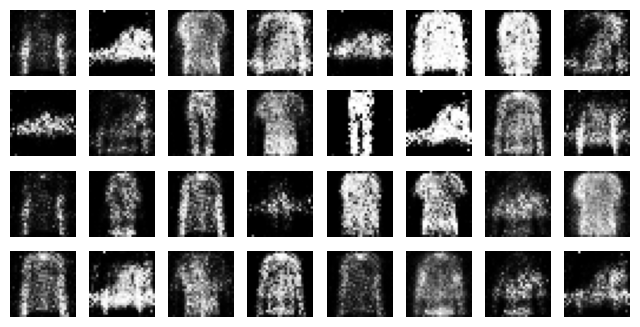

Epoch 14/30: disc-loss = 0.5294533212473438, gen-loss = 1.3839598677720233


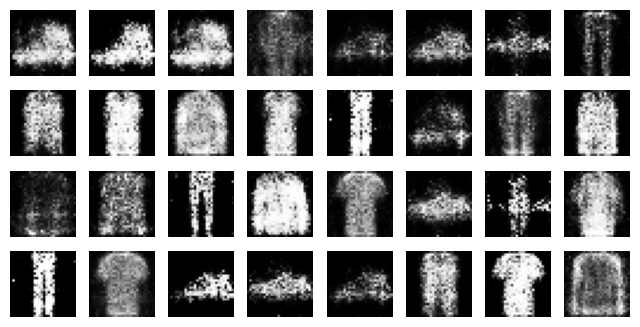

Epoch 15/30: disc-loss = 0.5219881280212645, gen-loss = 1.388956309124163


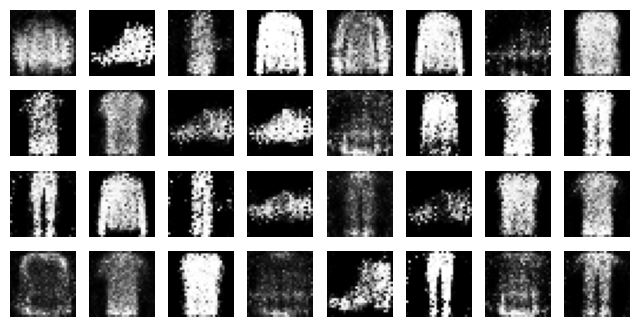

Epoch 16/30: disc-loss = 0.5349718812544635, gen-loss = 1.351112050994946


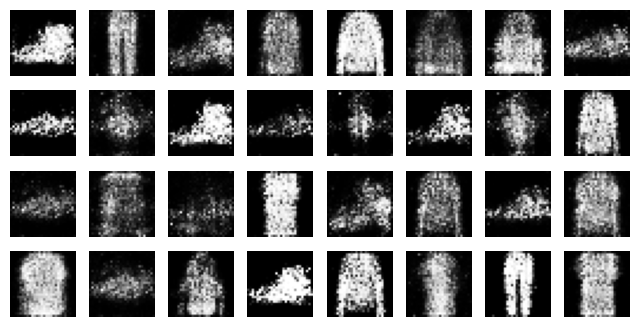

Epoch 17/30: disc-loss = 0.5501914470438745, gen-loss = 1.2892073286566765


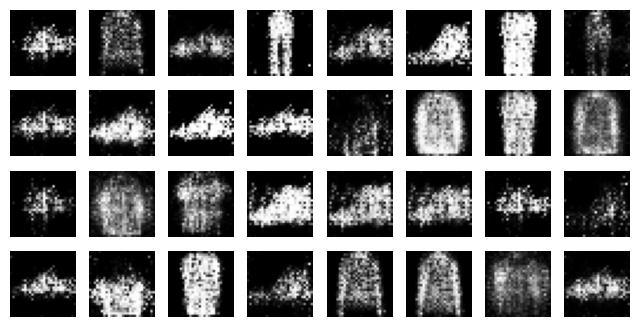

Epoch 18/30: disc-loss = 0.5467491364403135, gen-loss = 1.3302023118468607


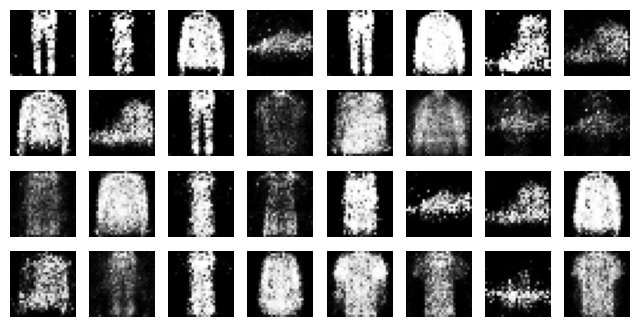

Epoch 19/30: disc-loss = 0.5589239743484813, gen-loss = 1.2705908687251388


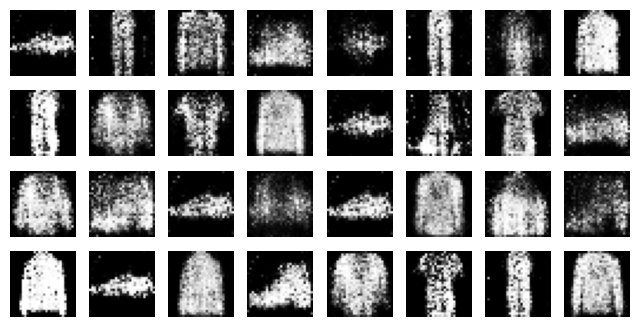

Epoch 20/30: disc-loss = 0.5704960993900421, gen-loss = 1.1916127516205903


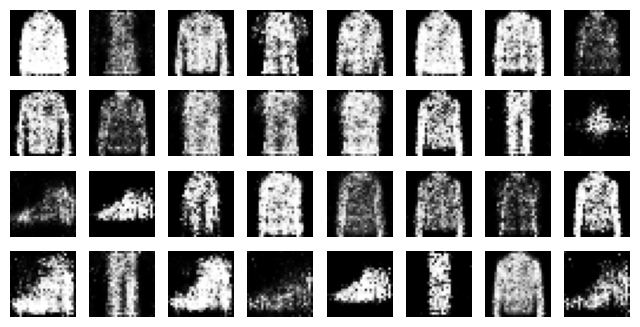

Epoch 21/30: disc-loss = 0.5719888893661985, gen-loss = 1.172503605769698


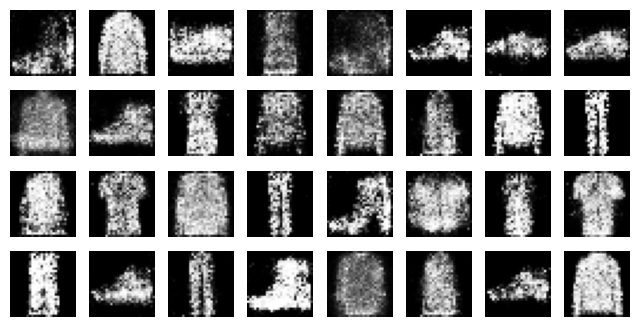

Epoch 22/30: disc-loss = 0.5790404041481626, gen-loss = 1.1585423809707545


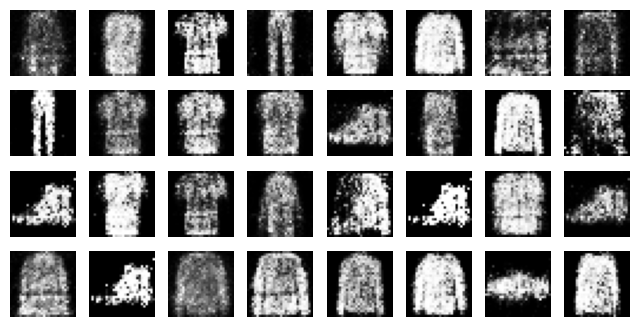

Epoch 23/30: disc-loss = 0.5780843794345856, gen-loss = 1.1367545002585004


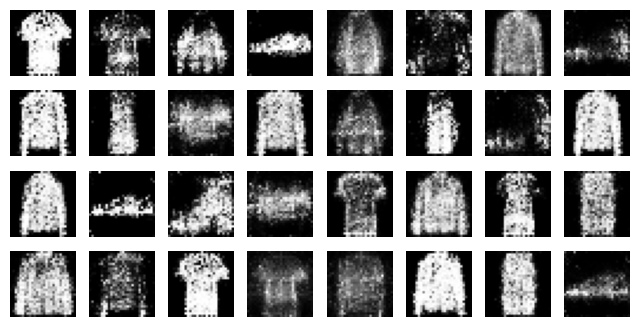

Epoch 24/30: disc-loss = 0.5971342847225772, gen-loss = 1.0917362016477403


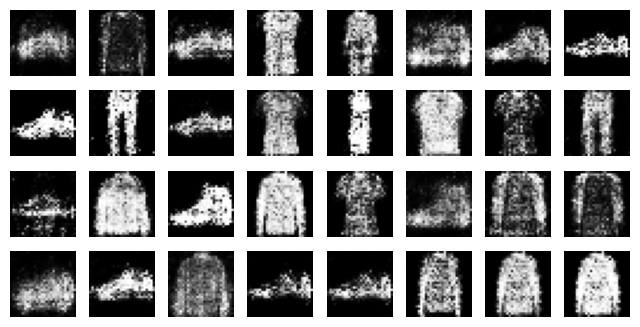

Epoch 25/30: disc-loss = 0.5942024406354138, gen-loss = 1.1122624323626233


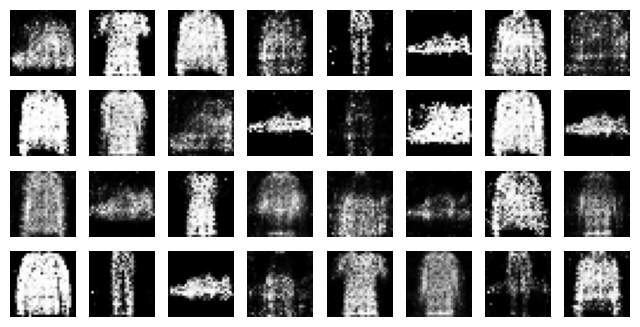

Epoch 26/30: disc-loss = 0.5972179030157199, gen-loss = 1.0950157251327661


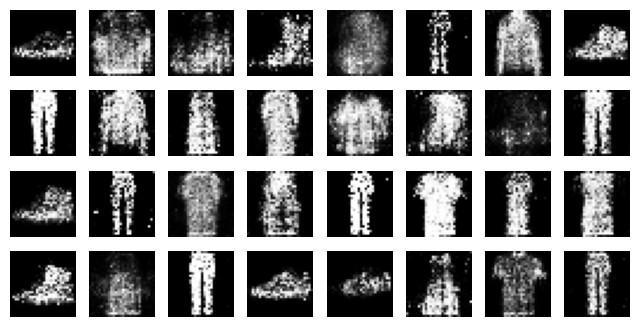

Epoch 27/30: disc-loss = 0.6016334804000368, gen-loss = 1.0773632108785545


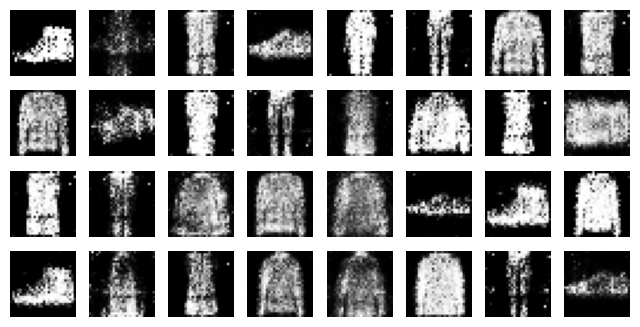

Epoch 28/30: disc-loss = 0.6011600951859906, gen-loss = 1.0554214488169191


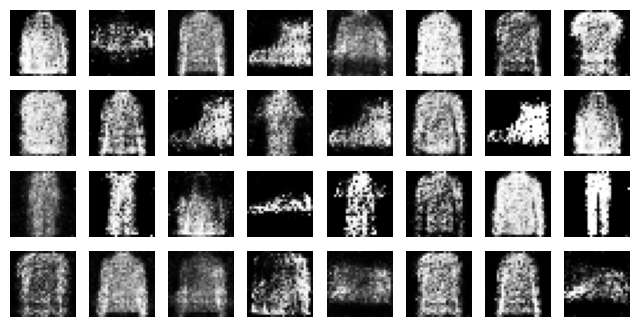

Epoch 29/30: disc-loss = 0.5992310586248993, gen-loss = 1.0728814917005551


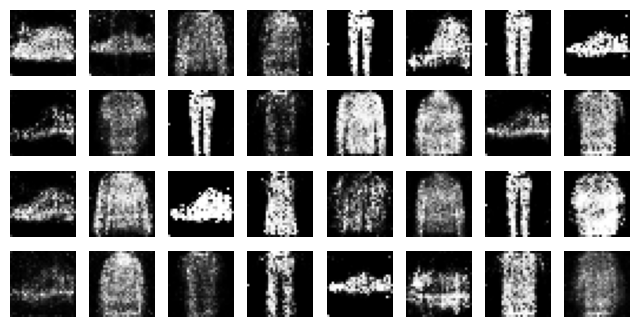

Epoch 30/30: disc-loss = 0.5947418630502785, gen-loss = 1.0933702720957956


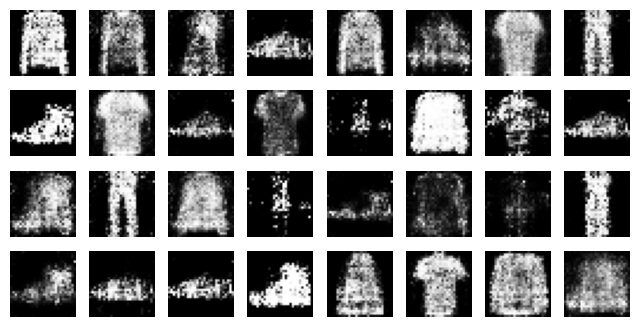

In [ ]:
standard_GAN.train()

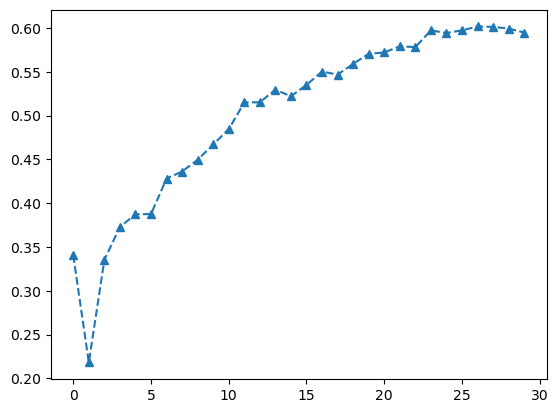

In [ ]:
plt.plot(standard_GAN.history['disc-loss'], "--^")
plt.show()

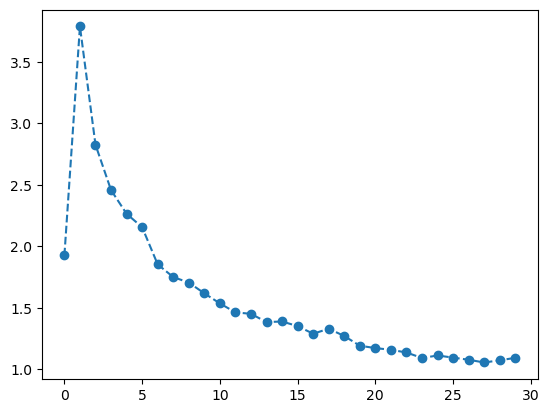

In [ ]:
plt.plot(standard_GAN.history['gen-loss'], "--o")
plt.show()

## <font color="#0b486b">II.4. Deep Convolutional GAN (DCGAN)</font>

We now use the architecture of DCGAN to improve the quality of generated images.

In [ ]:
class DCGAN(GAN):
    def __init__(self, data_loader=None, batch_size=32, epochs=10, optimizer=None, noise_dim=30, device='cpu'):
        super(DCGAN, self).__init__(data_loader, batch_size, epochs, optimizer, noise_dim, device)

    def build(self):
        # Generator: Upscales noise to images
        self.generator = nn.Sequential(
            nn.Linear(self.noise_dim, 7 * 7 * 128),  # Upscale noise
            nn.BatchNorm1d(7 * 7 * 128),
            nn.ReLU(inplace=True),
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh()  # Output between -1 and 1
        ).to(self.device)

        # Discriminator: Classifies images as real or fake
        self.discriminator = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),  # Downsample
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.4),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),  # Further downsample
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.4),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),  # Single output
            nn.Sigmoid()  # Probability output
        ).to(self.device)

        # Optimizers for both networks
        self.dis_optimizer = self.optimizer(self.discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
        self.gen_optimizer = self.optimizer(self.generator.parameters(), lr=2e-4, betas=(0.5, 0.999))


We reshape `X_train` to 3D tensor of $[28, 28, 1]$ and also scale the input to $[-1,1]$.

In [ ]:
dc_gan = DCGAN(data_loader=train_loader, batch_size=128, noise_dim=100, optimizer=optim.Adam, epochs=30, device=device)

In [ ]:
dc_gan.build()

Epoch 1/30: disc-loss = 0.21672267510680257, gen-loss = 2.7731156633917693


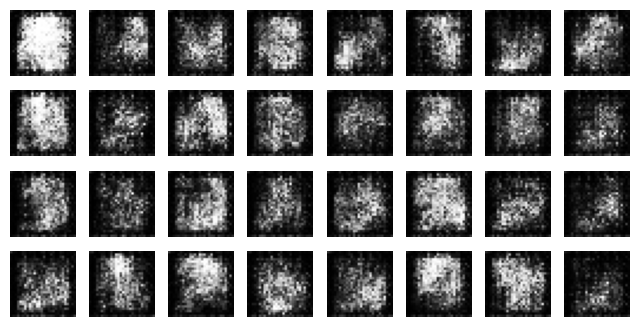

Epoch 2/30: disc-loss = 0.5518365931359066, gen-loss = 1.0443323546913779


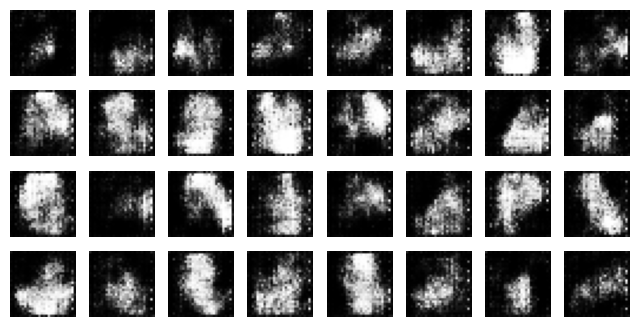

Epoch 3/30: disc-loss = 0.6092141483240067, gen-loss = 0.8906877162350211


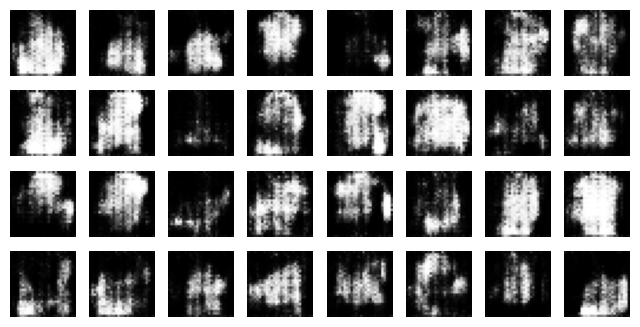

Epoch 4/30: disc-loss = 0.5965444772106827, gen-loss = 1.0106206885568656


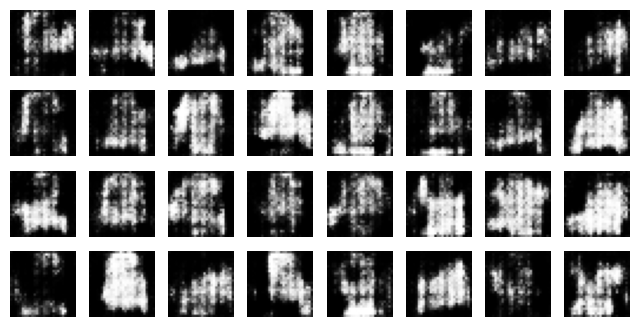

Epoch 5/30: disc-loss = 0.5647217513649327, gen-loss = 1.0701844206281528


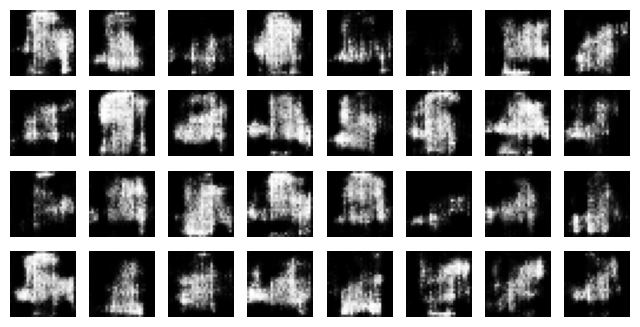

Epoch 6/30: disc-loss = 0.5281373947668987, gen-loss = 1.181770192210082


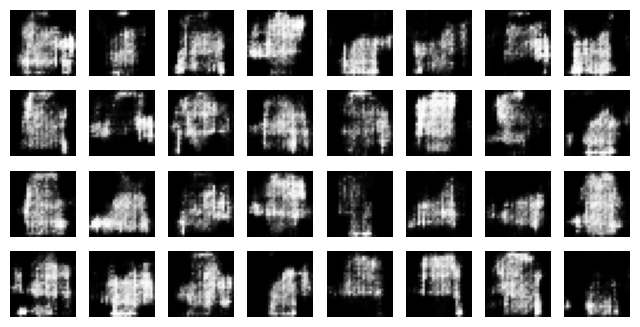

Epoch 7/30: disc-loss = 0.4892527679349207, gen-loss = 1.267947889816989


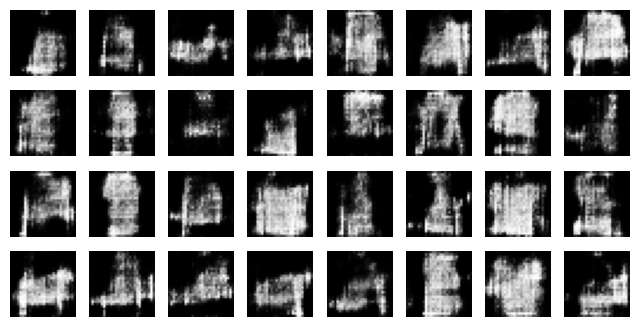

Epoch 8/30: disc-loss = 0.470152326070579, gen-loss = 1.64809567077904


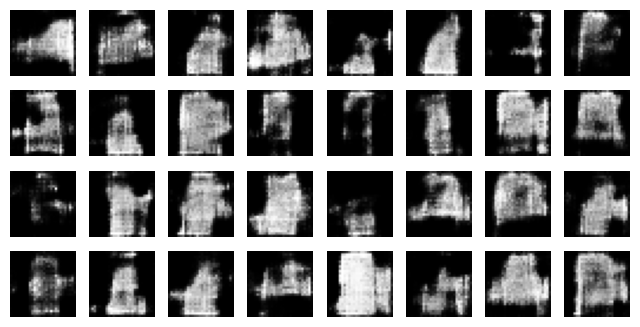

Epoch 9/30: disc-loss = 0.47945664870511195, gen-loss = 1.3726419897595787


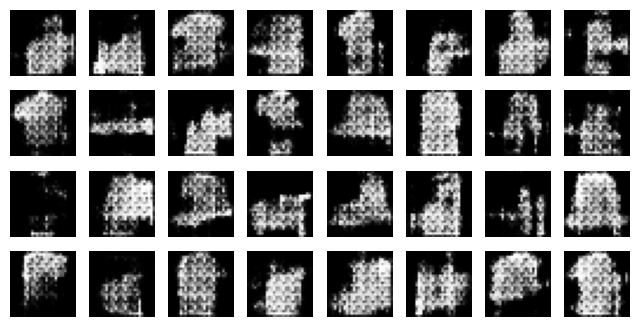

Epoch 10/30: disc-loss = 0.48701104749539853, gen-loss = 1.5278351094312728


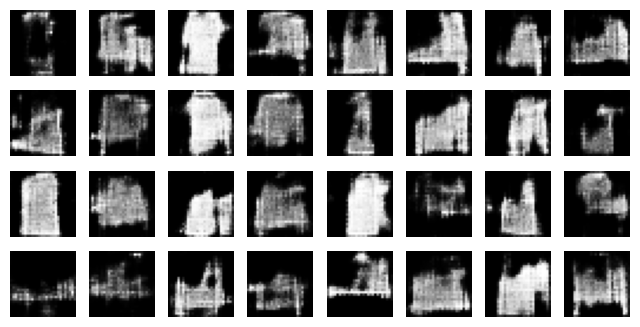

Epoch 11/30: disc-loss = 0.4999517274510329, gen-loss = 1.429072966241533


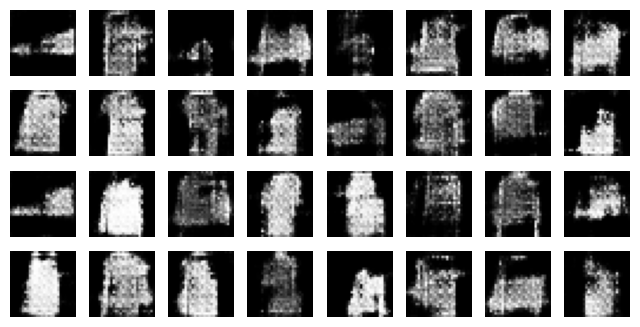

Epoch 12/30: disc-loss = 0.5296220274487878, gen-loss = 1.272911892954711


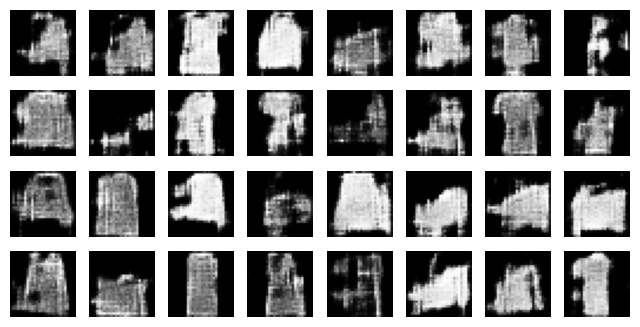

Epoch 13/30: disc-loss = 0.5282071033480821, gen-loss = 1.2657144043096311


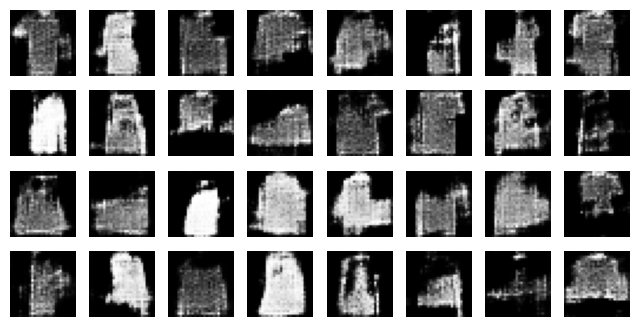

Epoch 14/30: disc-loss = 0.5368751731647807, gen-loss = 1.2337951367827737


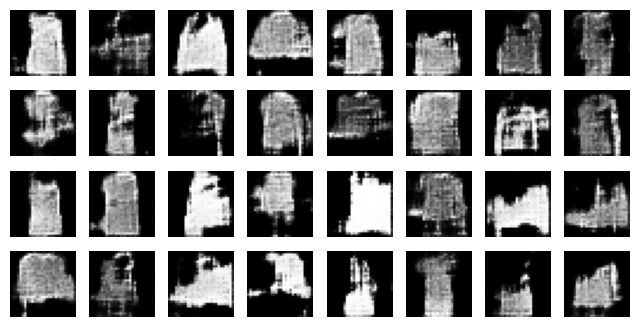

Epoch 15/30: disc-loss = 0.5465414907522262, gen-loss = 1.2478730989869233


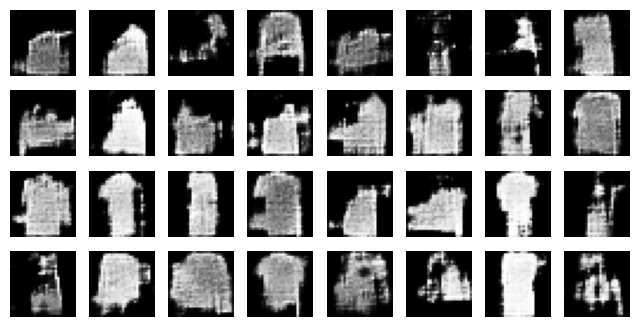

Epoch 16/30: disc-loss = 0.5540288113484717, gen-loss = 1.260401994939063


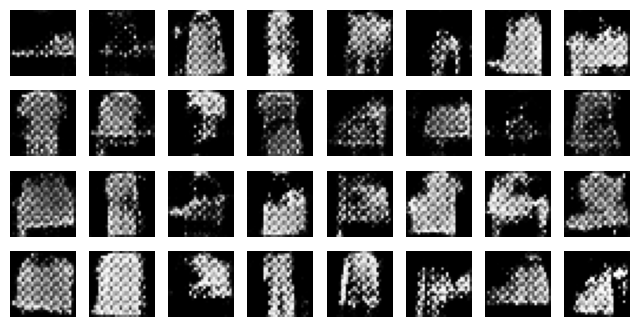

Epoch 17/30: disc-loss = 0.5647191230658513, gen-loss = 1.2826566084934647


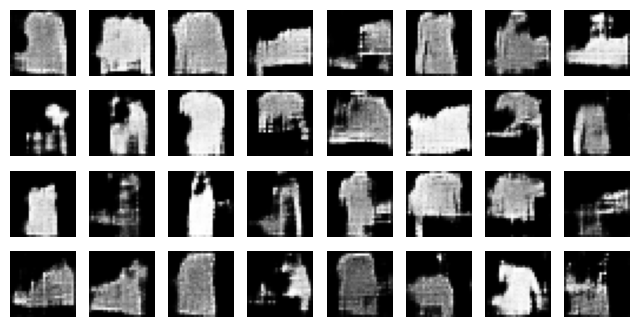

Epoch 18/30: disc-loss = 0.5645973549526968, gen-loss = 1.1578246123471838


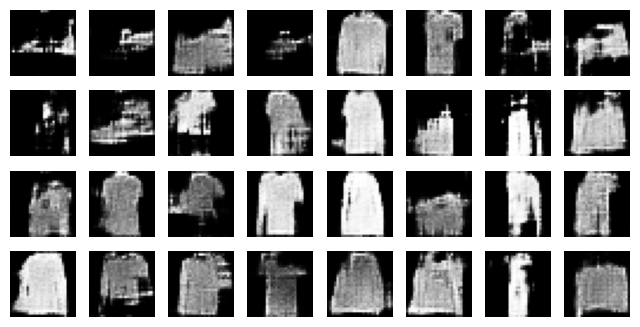

Epoch 19/30: disc-loss = 0.5603627847258452, gen-loss = 1.1564113535698812


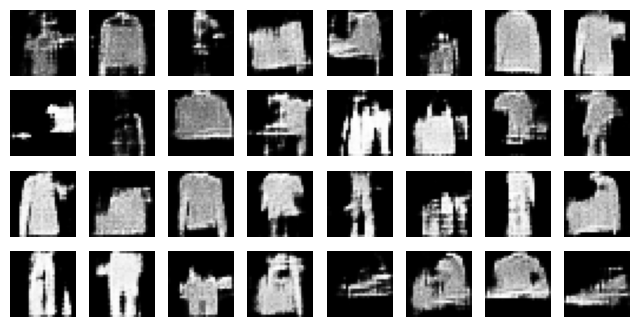

Epoch 20/30: disc-loss = 0.5667250072880156, gen-loss = 1.1741079608346248


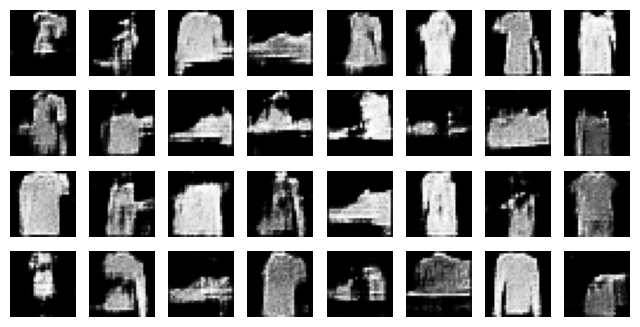

Epoch 21/30: disc-loss = 0.5720404673154187, gen-loss = 1.2180912035286047


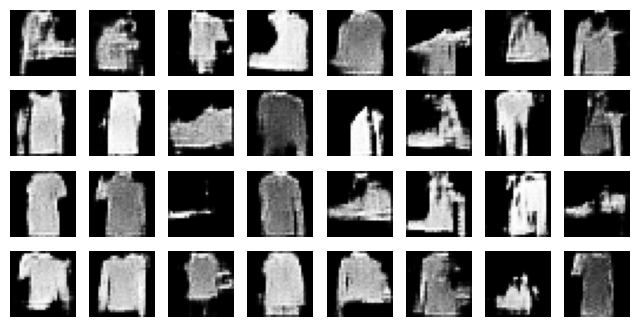

Epoch 22/30: disc-loss = 0.5741300180459478, gen-loss = 1.1487083936193188


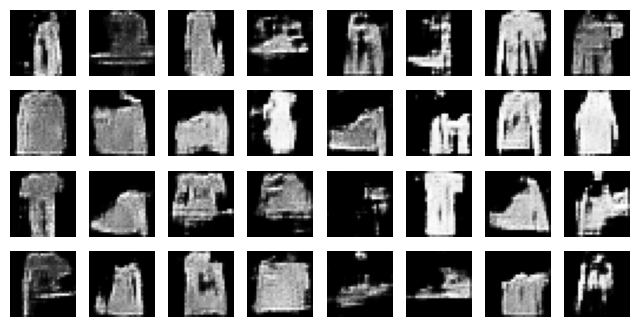

Epoch 23/30: disc-loss = 0.5854826337972264, gen-loss = 1.1464876969149158


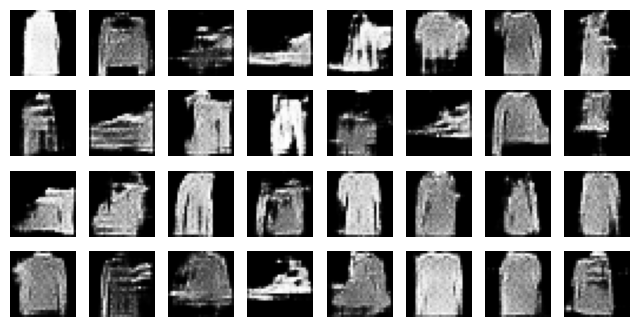

Epoch 24/30: disc-loss = 0.590264854917101, gen-loss = 1.2948220649342628


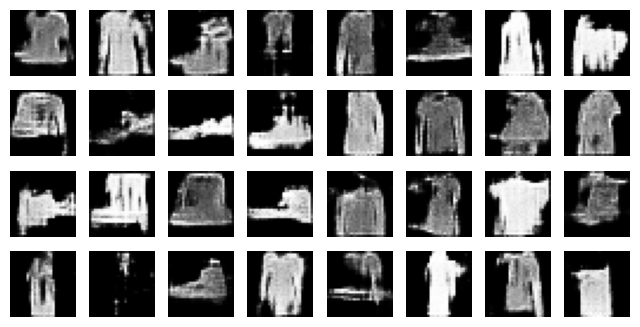

Epoch 25/30: disc-loss = 0.6028468251987628, gen-loss = 1.1183206173265057


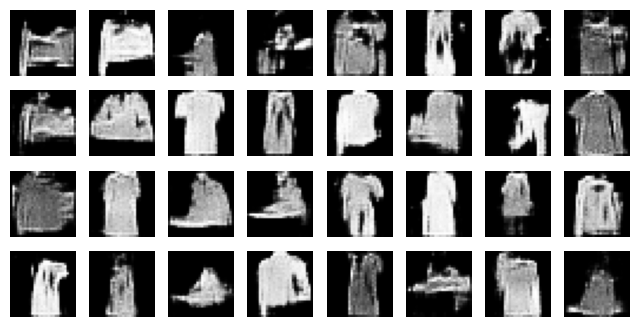

Epoch 26/30: disc-loss = 0.6023417901081644, gen-loss = 1.1094240751236109


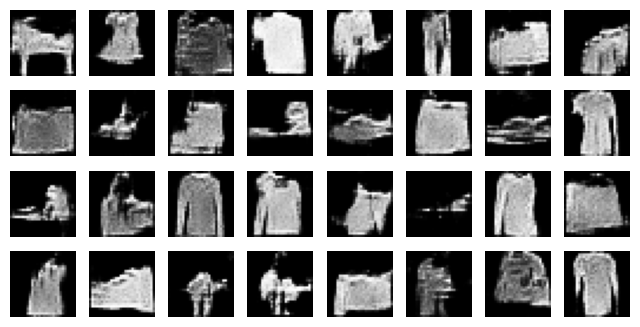

Epoch 27/30: disc-loss = 0.6074100195602247, gen-loss = 1.1077700731860605


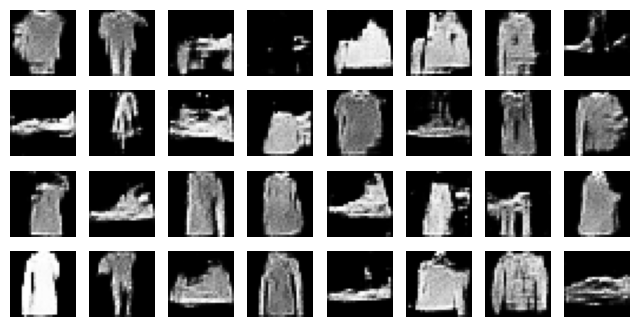

Epoch 28/30: disc-loss = 0.6038591030297006, gen-loss = 1.0944204827782456


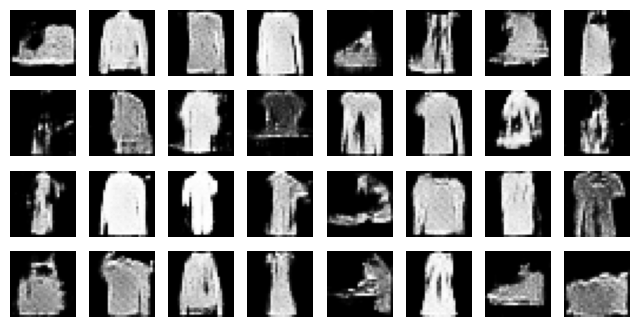

Epoch 29/30: disc-loss = 0.6093373701071284, gen-loss = 1.0898335302711293


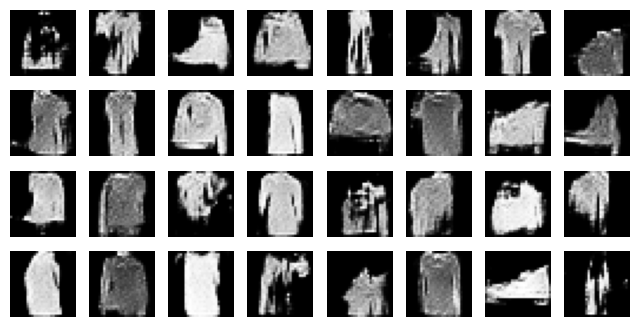

Epoch 30/30: disc-loss = 0.6137015360176183, gen-loss = 1.087505199347332


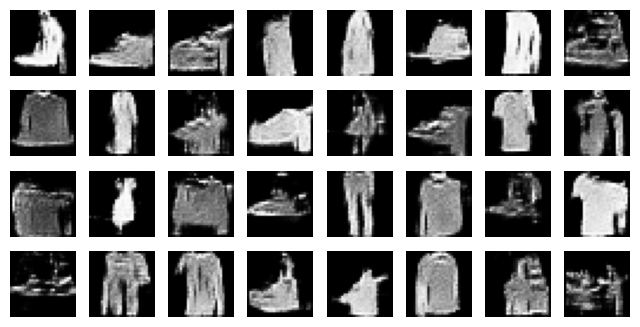

In [ ]:
dc_gan.train()

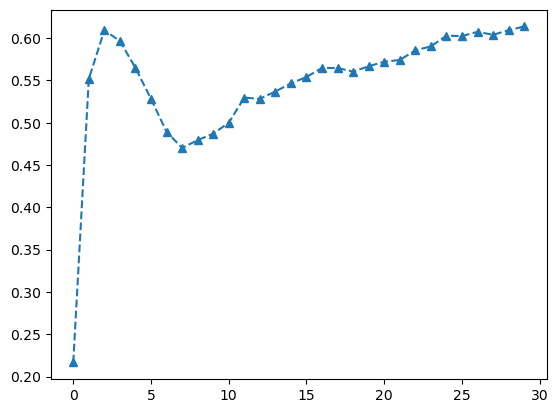

In [ ]:
plt.plot(dc_gan.history['disc-loss'], "--^")
plt.show()

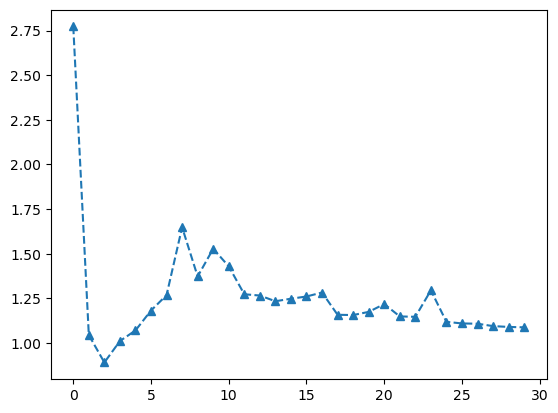

In [ ]:
plt.plot(dc_gan.history['gen-loss'], "--^")
plt.show()

## <font color="#0b486b">II.5. Additional Reading: Wasserstein GAN with Gradient Penalty</font> <font color="red">***</font>

In this section, we will implement an improved version of GANs by replacing the original gan loss with the Wasserstein distance. This idea can significantly reduce the mode collapse problem in GAN. You can refer to the [WGAN paper](https://arxiv.org/abs/1701.07875) and a [nice tutorial here](https://medium.com/@jonathan_hui/gan-wasserstein-gan-wgan-gp-6a1a2aa1b490) for more details. In practice, WGAN uses the gradient clipping method to avoid the gradients go too strong however this trick still makes unstable training. Recently, we use an improved version of WGAN called WGAN-GP (WGAN with gradient penalty) which replacing the gradient clipping technique with gradient penalty constraint.

The objective of WGAN-GP is as below:
\begin{equation}
   \underset{G}{\text{minimize}} \; \underset{D}{\text{maximize}} \;  \mathbb{E}_{x \sim p_{d}}[D(x)] - \mathbb{E}_{z \sim p_{z}} [D(G(z))] - \alpha \mathbb{E}_{\hat{x} \sim p_{\hat{x}}} [(\|\nabla_{\hat{x}} D(\hat{x})\|_2 - 1)^2]
\end{equation}


In [ ]:
class WassersteinGAN_GP(GAN):
    def __init__(self, data_loader=None, batch_size=32, epochs=10, optimizer=None,
                 noise_dim=64, n_train_g=2, alpha=10.0, device='cpu'):
        super(WassersteinGAN_GP, self).__init__(data_loader, batch_size, epochs, optimizer, noise_dim, device)
        self.alpha = alpha  # Weight for the gradient penalty
        self.n_train_g = n_train_g  # Number of generator updates per discriminator update

    def build(self):
        # Build the generator network
        self.generator = nn.Sequential(
            nn.Linear(self.noise_dim, 7 * 7 * 128),
            nn.BatchNorm1d(7 * 7 * 128),
            nn.ReLU(inplace=True),
            nn.Unflatten(1, (128, 7, 7)),  # Reshape to 3D tensor
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # Transposed convolution for up-sampling
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),  # Final output layer
            nn.Tanh()  # Activation function to scale outputs to [-1, 1]
        ).to(self.device)

        # Build the discriminator network
        self.discriminator = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),  # Initial convolution for down-sampling
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.4),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),  # Further downsample
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.4),
            nn.Flatten(),  # Flatten the output for the final layer
            nn.Linear(128 * 7 * 7, 1),  # Fully connected layer to output a single score
            nn.Sigmoid()  # Sigmoid activation for outputting probabilities
        ).to(self.device)

        # Define optimizers for both generator and discriminator
        self.dis_optimizer = self.optimizer(self.discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
        self.gen_optimizer = self.optimizer(self.generator.parameters(), lr=2e-4, betas=(0.5, 0.999))

    def gradient_penalty(self, real_data, fake_data):
        # Calculate the gradient penalty for WGAN-GP
        alpha = torch.rand(real_data.size(0), 1, 1, 1, device=self.device)  # Random interpolation factor
        interpolates = alpha * real_data + (1 - alpha) * fake_data  # Create interpolated samples
        interpolates.requires_grad_(True)  # Enable gradient tracking

        dis_interpolates = self.discriminator(interpolates)  # Forward pass through the discriminator

        # Compute gradients of the discriminator's output with respect to interpolates
        gradients = torch.autograd.grad(outputs=dis_interpolates,
                                         inputs=interpolates,
                                         grad_outputs=torch.ones_like(dis_interpolates, device=self.device),
                                         create_graph=True,
                                         retain_graph=True)[0]

        grad_norm = gradients.view(gradients.size(0), -1).norm(2, dim=1)  # Calculate gradient norms
        gp = ((grad_norm - 1) ** 2).mean()  # Calculate the gradient penalty
        return gp

    def compute_losses(self, real_data):
        # Compute losses for the generator and discriminator
        z = torch.randn(real_data.size(0), self.noise_dim, device=self.device)  # Sample random noise
        fake_data = self.generator(z)  # Generate fake data from noise

        dis_gp = self.gradient_penalty(real_data, fake_data)  # Compute gradient penalty
        dis_loss = -torch.mean(self.discriminator(fake_data)) + torch.mean(self.discriminator(real_data)) + self.alpha * dis_gp
        gen_loss = torch.mean(self.discriminator(fake_data))  # Loss for the generator

        return dis_loss, gen_loss

    def train_one_batch(self, real_data):
        # Train the discriminator for one batch
        self.dis_optimizer.zero_grad()  # Clear gradients
        dis_loss, _ = self.compute_losses(real_data)  # Compute discriminator loss
        dis_loss.backward()  # Backpropagation
        self.dis_optimizer.step()  # Update discriminator

        # Train the generator multiple times
        for _ in range(self.n_train_g):
            self.gen_optimizer.zero_grad()  # Clear gradients
            _, gen_loss = self.compute_losses(real_data)  # Compute generator loss
            gen_loss.backward()  # Backpropagation
            self.gen_optimizer.step()  # Update generator

        return dis_loss.item(), gen_loss.item()  # Return losses

    def train(self):
        # Main training loop
        self.history = {'dis_loss': [], 'gen_loss': []}  # Store losses
        for epoch in range(self.epochs):
            dis_losses, gen_losses = [], []  # Track losses per epoch
            for batch_idx, (X_batch, _) in enumerate(self.data_loader):
                X_batch = X_batch.to(self.device)  # Move data to the specified device
                dis_loss, gen_loss = self.train_one_batch(X_batch)  # Train on the batch
                dis_losses.append(dis_loss)  # Store discriminator loss
                gen_losses.append(gen_loss)  # Store generator loss

            # Average and log losses for the epoch
            self.history['dis_loss'].append(np.mean(dis_losses))
            self.history['gen_loss'].append(np.mean(gen_losses))
            print(f"Epoch {epoch + 1}/{self.epochs}: dis_loss={np.mean(dis_losses):.4f} | gen_loss={np.mean(gen_losses):.4f}")

            # Generate and plot images after each epoch
            with torch.no_grad():
                generated_images = self.generate(32)  # Generate a set number of images
                WassersteinGAN_GP.plot_multiple_images(generated_images, n_cols=8)  # Plot generated images

    def generate(self, num_examples=None):
        # Generate images from random noise
        num_examples = self.batch_size if num_examples is None else num_examples  # Default to batch size if not specified
        z = torch.randn(num_examples, self.noise_dim, device=self.device)  # Sample random noise
        X_gen = self.generator(z)  # Generate images
        return X_gen  # Return generated images

In [ ]:
ws_gan = WassersteinGAN_GP(data_loader=train_loader, batch_size=128, noise_dim=100, optimizer=optim.Adam, epochs=30, device=device)

In [ ]:
ws_gan.build()

Epoch 1/30: dis_loss=6.1120 | gen_loss=0.5137


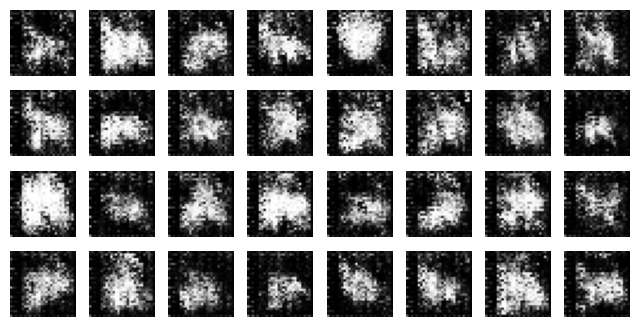

Epoch 2/30: dis_loss=3.0856 | gen_loss=0.3648


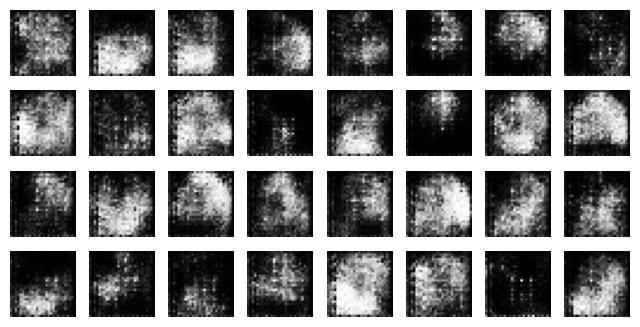

Epoch 3/30: dis_loss=1.5923 | gen_loss=0.3603


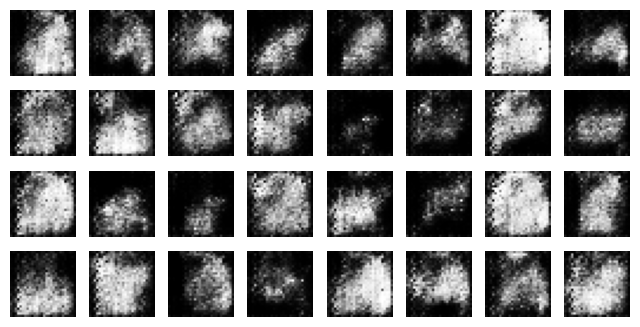

Epoch 4/30: dis_loss=1.2749 | gen_loss=0.3640


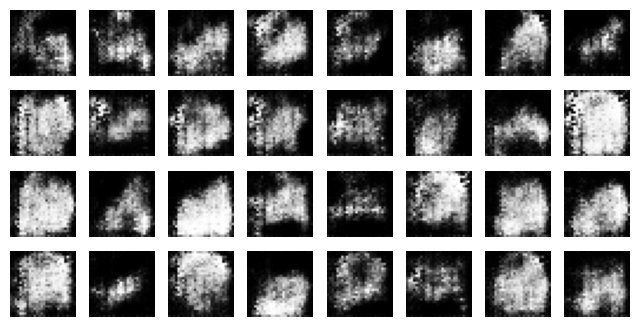

Epoch 5/30: dis_loss=1.0618 | gen_loss=0.3817


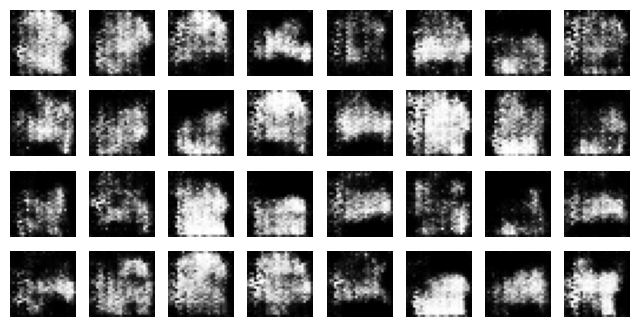

Epoch 6/30: dis_loss=0.8097 | gen_loss=0.3980


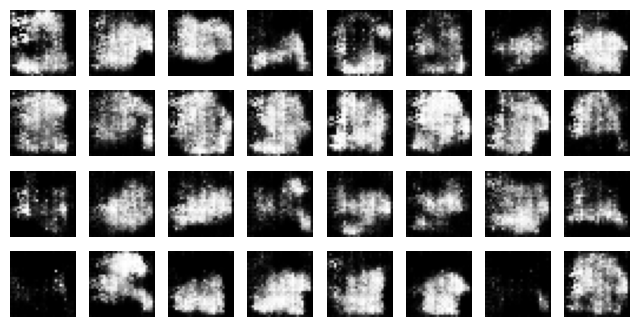

Epoch 7/30: dis_loss=0.6888 | gen_loss=0.4120


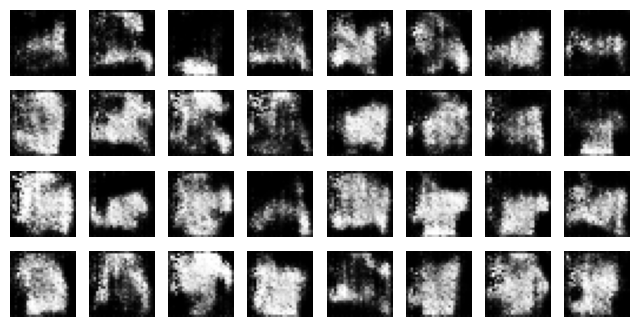

Epoch 8/30: dis_loss=0.6302 | gen_loss=0.4030


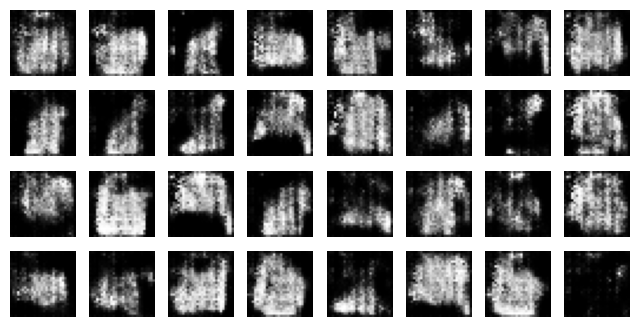

Epoch 9/30: dis_loss=0.5556 | gen_loss=0.4084


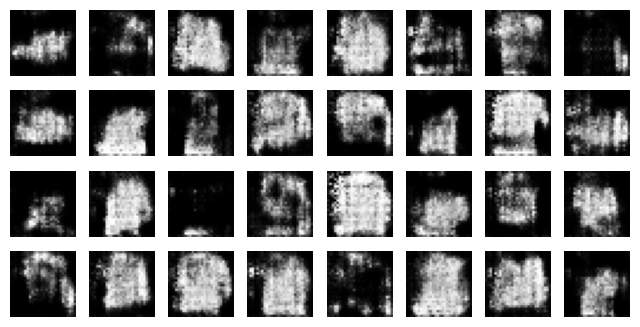

Epoch 10/30: dis_loss=0.5060 | gen_loss=0.3905


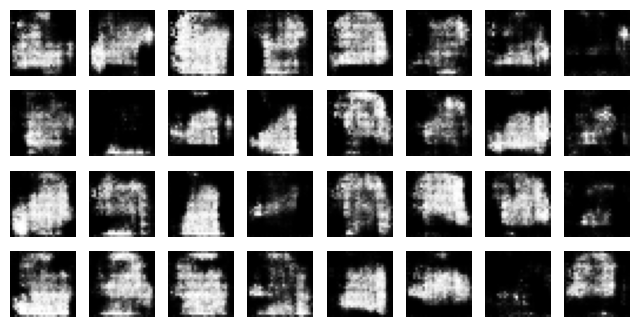

Epoch 11/30: dis_loss=0.4487 | gen_loss=0.3892


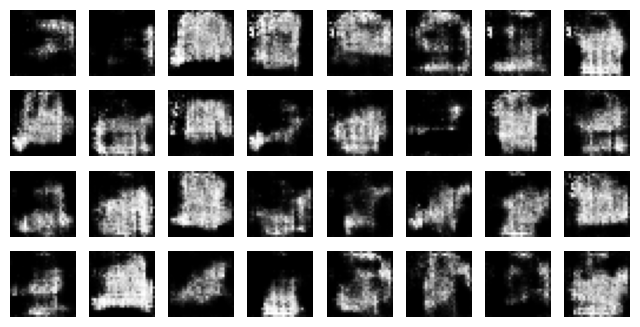

Epoch 12/30: dis_loss=0.4145 | gen_loss=0.3933


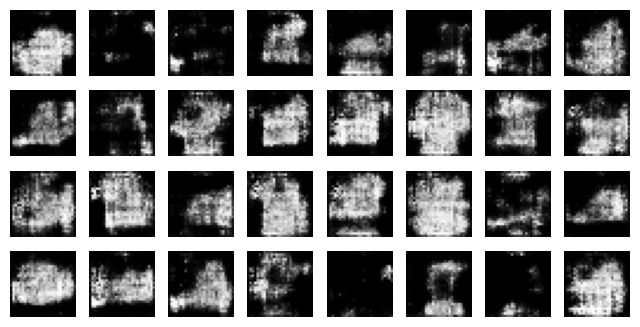

Epoch 13/30: dis_loss=0.3575 | gen_loss=0.3745


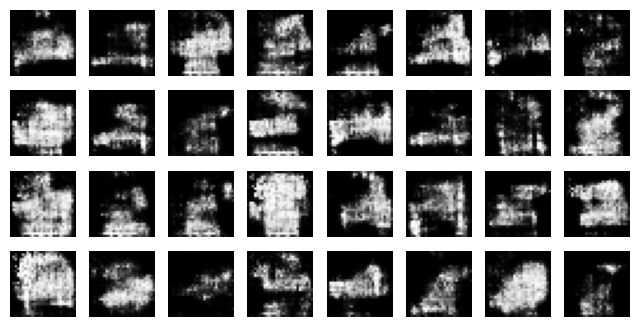

Epoch 14/30: dis_loss=0.3200 | gen_loss=0.3919


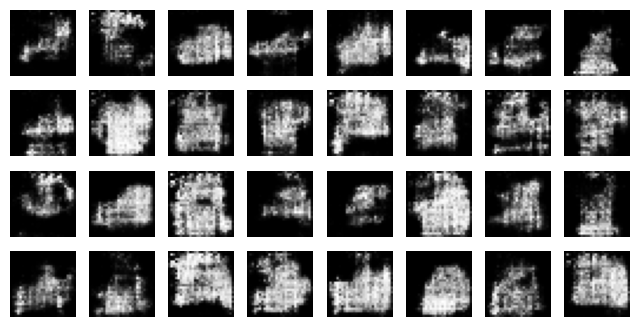

Epoch 15/30: dis_loss=0.2860 | gen_loss=0.4039


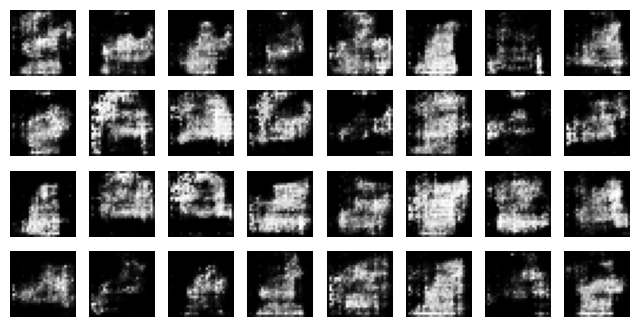

Epoch 16/30: dis_loss=0.2867 | gen_loss=0.3921


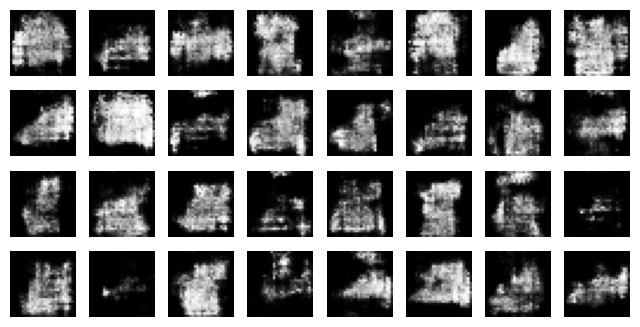

Epoch 17/30: dis_loss=0.2457 | gen_loss=0.4018


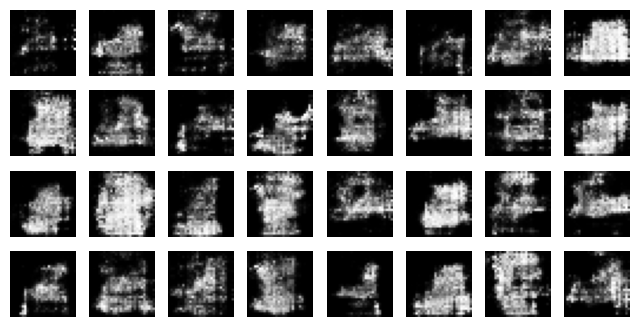

Epoch 18/30: dis_loss=0.2319 | gen_loss=0.4174


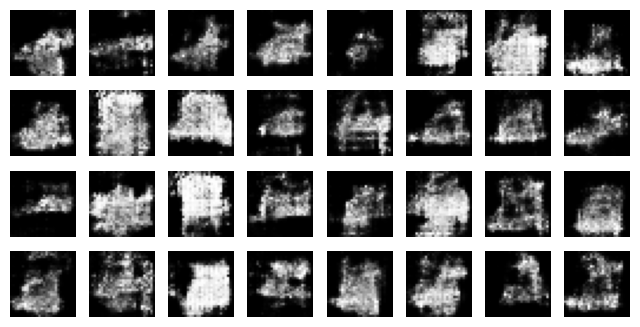

Epoch 19/30: dis_loss=0.2248 | gen_loss=0.4164


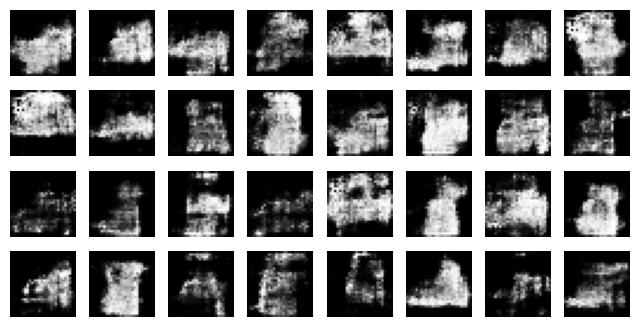

Epoch 20/30: dis_loss=0.2165 | gen_loss=0.4193


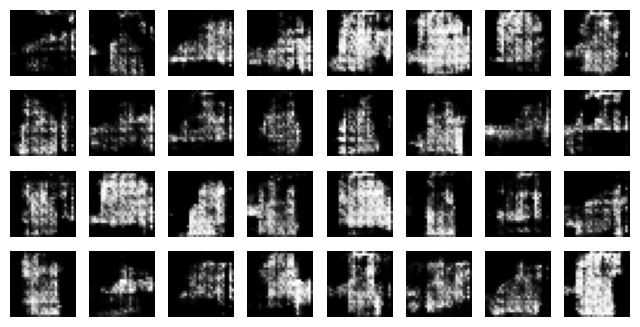

Epoch 21/30: dis_loss=0.1945 | gen_loss=0.4230


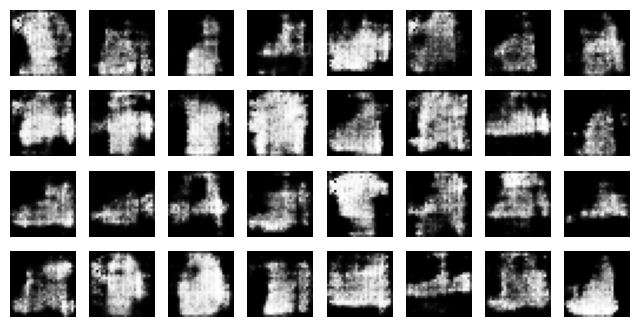

Epoch 22/30: dis_loss=0.1869 | gen_loss=0.4155


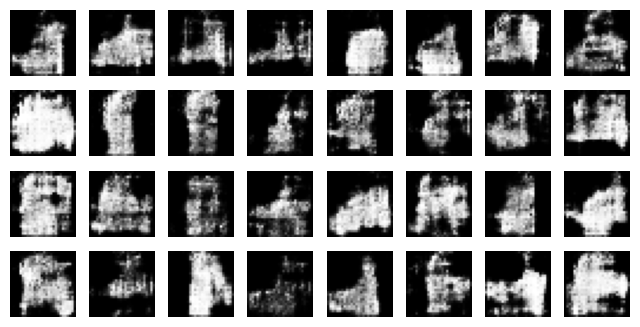

Epoch 23/30: dis_loss=0.1884 | gen_loss=0.4281


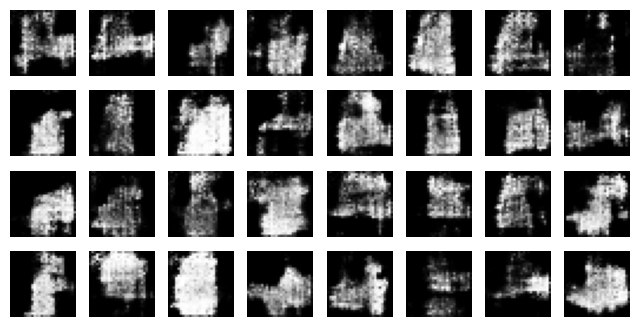

Epoch 24/30: dis_loss=0.1873 | gen_loss=0.4293


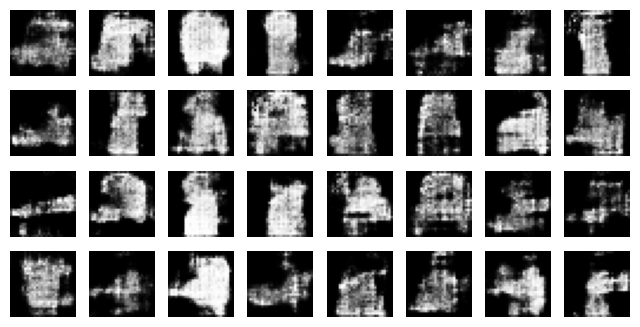

Epoch 25/30: dis_loss=0.1763 | gen_loss=0.4310


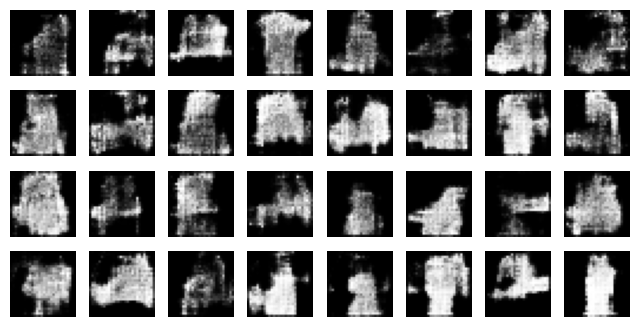

Epoch 26/30: dis_loss=0.1831 | gen_loss=0.4203


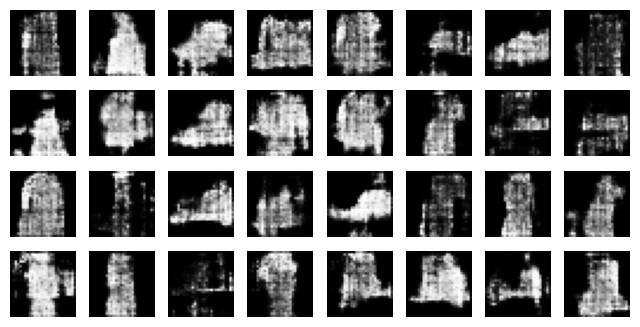

Epoch 27/30: dis_loss=0.1662 | gen_loss=0.4293


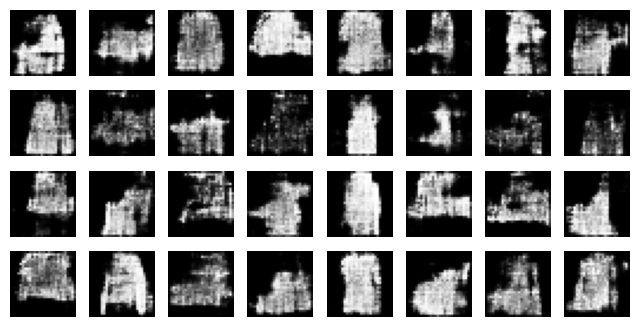

Epoch 28/30: dis_loss=0.1688 | gen_loss=0.4202


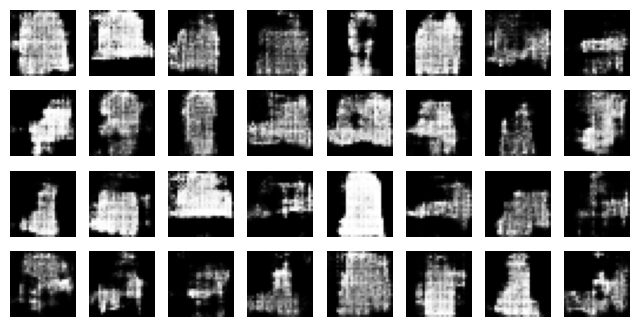

Epoch 29/30: dis_loss=0.1715 | gen_loss=0.4272


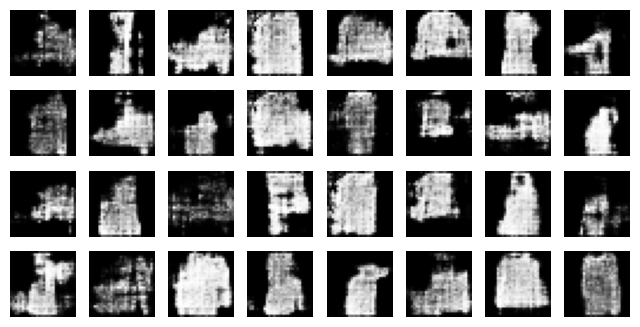

Epoch 30/30: dis_loss=0.1608 | gen_loss=0.4404


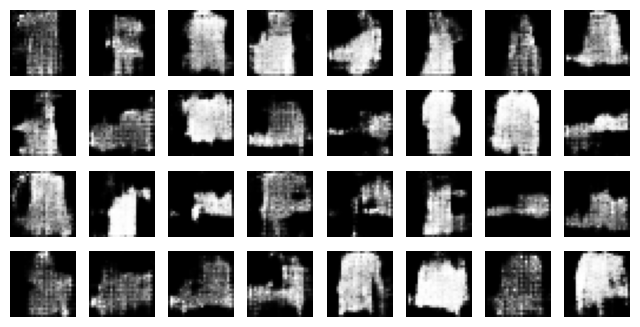

In [ ]:
ws_gan.train()

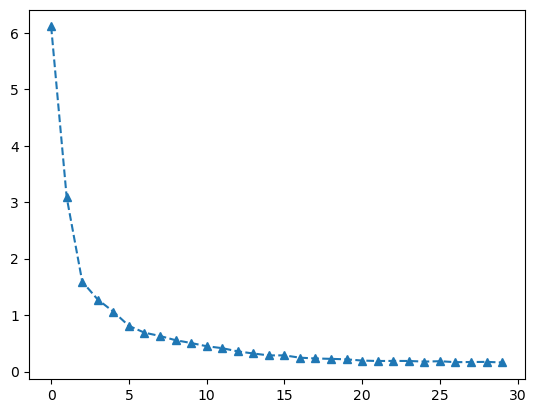

In [ ]:
plt.plot(ws_gan.history['dis_loss'], "--^")
plt.show()

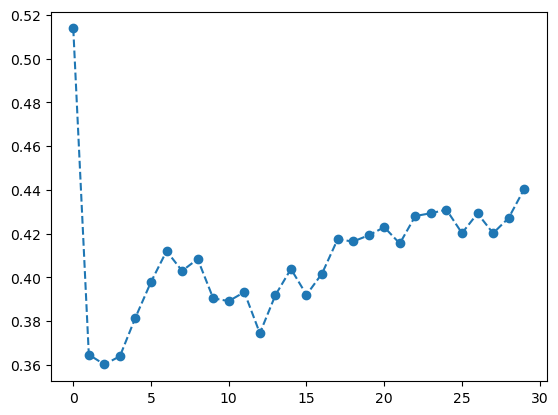

In [ ]:
plt.plot(ws_gan.history['gen_loss'], "--o")
plt.show()

**<font color="red">Exercise 1</font>**: Implement a function that allows us to compute the Inception score of a given GAN model. You then can make the comparison of the variants of GAN we implemented above. Below is the guideline of how to compute the Inception score.
- Train a classifier `C` on Fashion MNIST data using its labels (i.e., 1,2,...,10).
- Sample a batch $z_1,...,z_m$ of noises from the prior distribution ($m=200$).
- Feed  $z_1,...,z_m$ to the generator to obtain $\tilde{x}_i= G(z_i), i=1,...,m$.
- Compute the Inception score as:
  - $IS = exp\{\frac{1}{m}\sum_{i=1}^{m}{KL(C(\tilde{x}_i) || \frac{1}{m}\sum_{k=1}^{m}{C(\tilde{x_k})})}\}$.
- Refer to this [link](https://machinelearningmastery.com/how-to-implement-the-inception-score-from-scratch-for-evaluating-generated-images/) for a clear guide on how to compute the Inception score.

---
### <font color="#0b486b"> <div  style="text-align:center">**THE END**</div> </font>